<a href="https://colab.research.google.com/github/shrushtishinde45/Mobile-Sales-Analysis-PowerBI/blob/main/9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

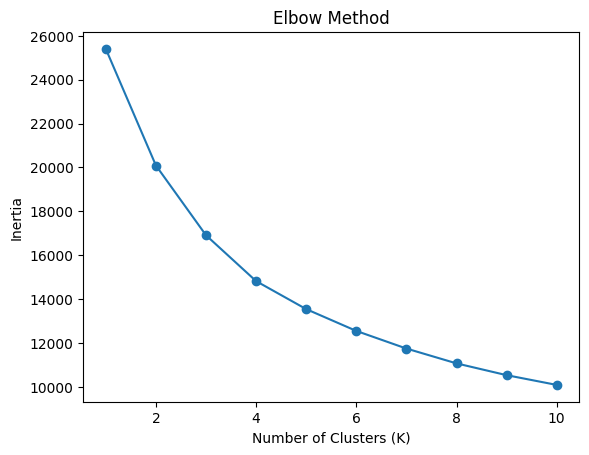

K-Means Results:
KMeans_Cluster
1    948
3    734
2    663
0    478
Name: count, dtype: int64


In [ ]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Load dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

# Select numerical data
numeric = df.select_dtypes(include="number").dropna()
numeric = numeric.loc[:, numeric.nunique() > 1]

# Standardize data
X = StandardScaler().fit_transform(numeric)

# Elbow Method
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertias.append(model.inertia_)

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

# K-Means Clustering
k = 4
df = df.loc[numeric.index].copy()

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X)

print("K-Means Results:")
print(df["KMeans_Cluster"].value_counts())